# IPL Batter Performance Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

matches = pd.read_csv("../data/cleaned/matches_clean.csv")
deliveries = pd.read_csv("../data/cleaned/deliveries_clean.csv")

## Business Question 1

Who are the highest run scorers in IPL history?

In [3]:
batter_runs = deliveries.groupby('batter')['batsman_runs'].sum().sort_values(ascending=False)
batter_runs.head(20)

batter
V Kohli           8014
S Dhawan          6769
RG Sharma         6630
DA Warner         6567
SK Raina          5536
MS Dhoni          5243
AB de Villiers    5181
CH Gayle          4997
RV Uthappa        4954
KD Karthik        4843
KL Rahul          4689
AM Rahane         4642
F du Plessis      4571
SV Samson         4419
AT Rayudu         4348
G Gambhir         4217
SR Watson         3880
MK Pandey         3859
SA Yadav          3594
JC Buttler        3583
Name: batsman_runs, dtype: int64

In [4]:
top_batters = batter_runs.reset_index()
top_batters.columns = ["Batter", "Runs"]
top_batters.head(20)

,Batter,Runs
0,V Kohli,8014
1,S Dhawan,6769
2,RG Sharma,6630
3,DA Warner,6567
4,SK Raina,5536
5,MS Dhoni,5243
6,AB de Villiers,5181
7,CH Gayle,4997
8,RV Uthappa,4954
9,KD Karthik,4843


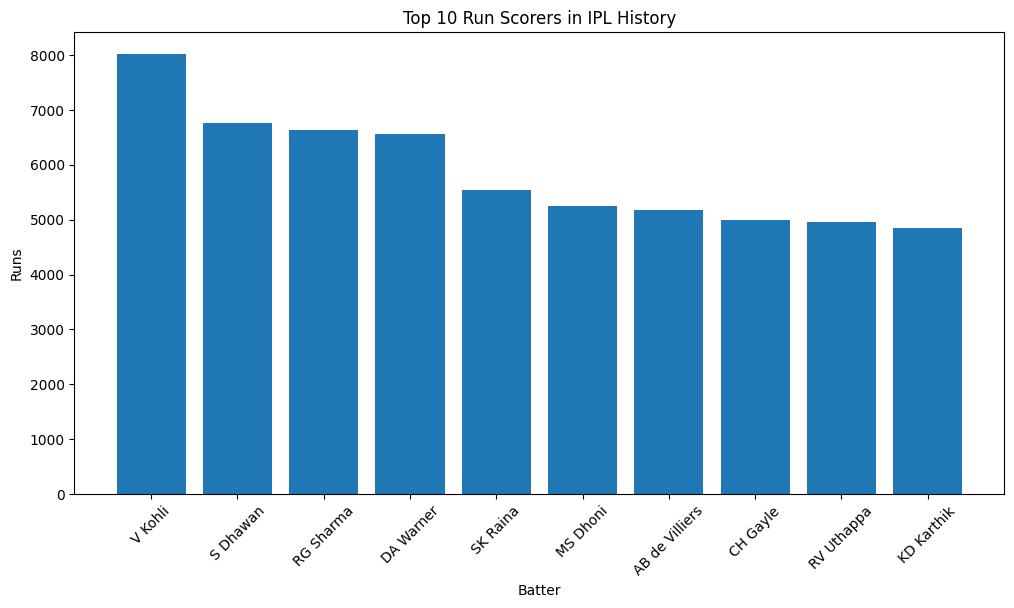

In [5]:
plt.figure(figsize=(12,6))

plt.bar(top_batters.head(10)['Batter'], top_batters.head(10)['Runs'])

plt.title('Top 10 Run Scorers in IPL History')

plt.xlabel('Batter')
plt.ylabel('Runs')

plt.xticks(rotation=45)

plt.show()

## Insight

This analysis identifies the most productive batters in IPL history based on total runs scored.

These players have consistently contributed across multiple seasons and represent long-term batting performance.

## Business Question 2

Which batters score runs most efficiently?

In [6]:
batter_runs = deliveries.groupby('batter')['batsman_runs'].sum()

In [7]:
deliveries['extras_type'].value_counts()

extras_type
wides      8380
legbyes    4001
noballs    1069
byes        673
penalty       2
Name: count, dtype: int64

In [8]:
balls_faced = deliveries[deliveries['extras_type'] != 'wides'].groupby('batter').size().sort_values()

In [9]:
batter_stats = pd.DataFrame({
    'Runs': batter_runs,
    'Balls_Faced': balls_faced
})

batter_stats = batter_stats.fillna(0)

In [10]:
batter_stats['Strike_Rate'] = ((batter_stats['Runs'] / batter_stats['Balls_Faced']) * 100).round(2)

In [11]:
batter_stats = batter_stats[batter_stats['Runs'] >= 1000]

In [12]:
batter_stats.sort_values(by='Strike_Rate', ascending=False).head(20)

,Runs,Balls_Faced,Strike_Rate
batter,,,
AD Russell,2488,1423,174.84
SP Narine,1534,925,165.84
N Pooran,1769,1092,162.00
GJ Maxwell,2772,1769,156.70
V Sehwag,2728,1755,155.44
Abhishek Sharma,1377,887,155.24
SO Hetmyer,1243,812,153.08
AB de Villiers,5181,3411,151.89
YBK Jaiswal,1607,1067,150.61


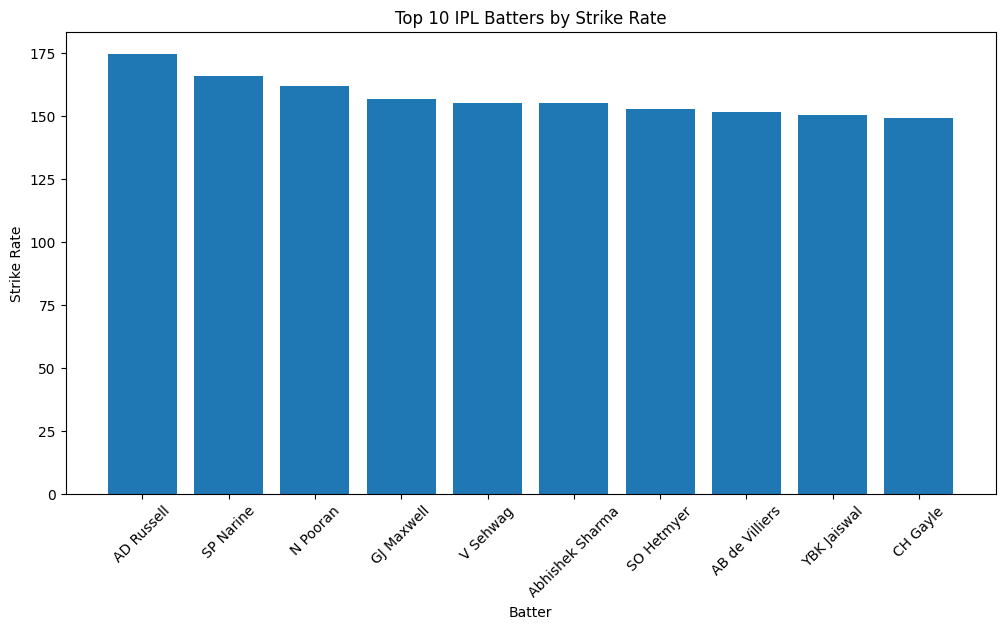

In [13]:
top_sr = (batter_stats.sort_values(by='Strike_Rate', ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(top_sr.index, top_sr['Strike_Rate'])

plt.title('Top 10 IPL Batters by Strike Rate')

plt.xlabel('Batter')
plt.ylabel('Strike Rate')

plt.xticks(rotation=45)

plt.show()

## Insight

Strike Rate measures scoring efficiency.

Unlike total runs, Strike Rate captures how quickly a batter scores, making it one of the most important performance metrics in T20 cricket.

A minimum runs filter was applied to remove small-sample outliers.

## Business Question 3

Which batters score boundaries most frequently?

In [14]:
fours = deliveries[deliveries['batsman_runs'] == 4].groupby('batter').size()

In [15]:
sixes = deliveries[deliveries['batsman_runs'] == 6].groupby('batter').size()

In [16]:
boundary_stats = pd.DataFrame({
    'Fours': fours,
    'Sixes': sixes
}).fillna(0)

In [17]:
boundary_stats['Total_Boundaries'] = (boundary_stats['Fours'] + boundary_stats['Sixes'])

In [18]:
boundary_stats['Runs'] = batter_runs

In [19]:
boundary_stats['Boundary_Runs'] = (boundary_stats['Fours'] * 4 + boundary_stats['Sixes'] * 6)

In [20]:
boundary_stats['Boundary_Run_%'] = (boundary_stats['Boundary_Runs'] / boundary_stats['Runs']) * 100

In [21]:
boundary_stats = boundary_stats[boundary_stats['Runs'] >= 1000]

In [22]:
boundary_stats.sort_values(by='Boundary_Run_%',ascending=False).head(20)

,Fours,Sixes,Total_Boundaries,Runs,Boundary_Runs,Boundary_Run_%
batter,,,,,,
SP Narine,164.0,97.0,261.0,1534,1238.0,80.704042
AD Russell,171.0,209.0,380.0,2488,1938.0,77.893891
CH Gayle,408.0,359.0,767.0,4997,3786.0,75.765459
YBK Jaiswal,199.0,64.0,263.0,1607,1180.0,73.428749
AC Gilchrist,239.0,92.0,331.0,2069,1508.0,72.885452
V Sehwag,334.0,106.0,440.0,2728,1972.0,72.287390
DR Smith,245.0,117.0,362.0,2385,1682.0,70.524109
PP Shaw,238.0,61.0,299.0,1892,1318.0,69.661734
CA Lynn,132.0,66.0,198.0,1329,924.0,69.525959


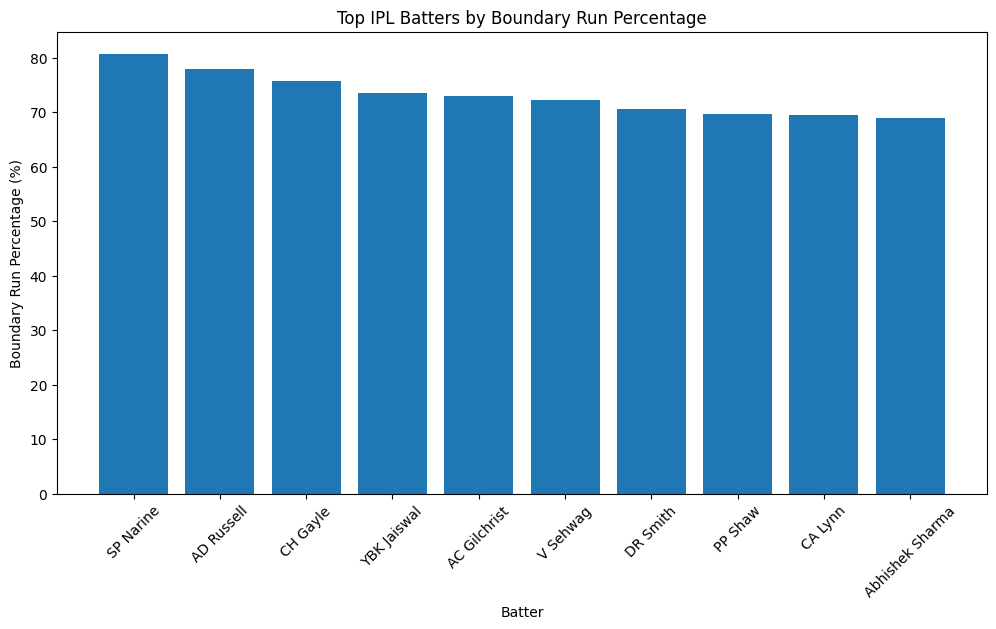

In [23]:
top_boundary_pct = (boundary_stats.sort_values(by='Boundary_Run_%',ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_boundary_pct.index,
    top_boundary_pct['Boundary_Run_%']
)

plt.title('Top IPL Batters by Boundary Run Percentage')

plt.xlabel('Batter')
plt.ylabel('Boundary Run Percentage (%)')

plt.xticks(rotation=45)

plt.show()

## Insight

Boundary Run Percentage measures how much of a batter's scoring comes directly from fours and sixes.

A high percentage indicates an aggressive boundary-oriented batter, while a lower percentage suggests greater reliance on running between the wickets.

## Business Question 4

Which batters hit boundaries most frequently?

In [24]:
boundary_stats['Ball_Faced'] = balls_faced

In [25]:
boundary_stats['Boundary_Frequency'] = (boundary_stats['Ball_Faced'] / boundary_stats['Total_Boundaries'])

In [26]:
boundary_stats = boundary_stats[boundary_stats['Runs'] >= 1000]

In [27]:
boundary_stats.sort_values(by='Boundary_Frequency', ascending=True).head(20)

,Fours,Sixes,Total_Boundaries,Runs,Boundary_Runs,Boundary_Run_%,Ball_Faced,Boundary_Frequency
batter,,,,,,,,
SP Narine,164.0,97.0,261.0,1534,1238.0,80.704042,925,3.544061
AD Russell,171.0,209.0,380.0,2488,1938.0,77.893891,1423,3.744737
V Sehwag,334.0,106.0,440.0,2728,1972.0,72.287390,1755,3.988636
YBK Jaiswal,199.0,64.0,263.0,1607,1180.0,73.428749,1067,4.057034
PP Shaw,238.0,61.0,299.0,1892,1318.0,69.661734,1283,4.290970
CH Gayle,408.0,359.0,767.0,4997,3786.0,75.765459,3346,4.362451
Abhishek Sharma,128.0,73.0,201.0,1377,950.0,68.990559,887,4.412935
GJ Maxwell,233.0,160.0,393.0,2772,1892.0,68.253968,1769,4.501272
AC Gilchrist,239.0,92.0,331.0,2069,1508.0,72.885452,1495,4.516616


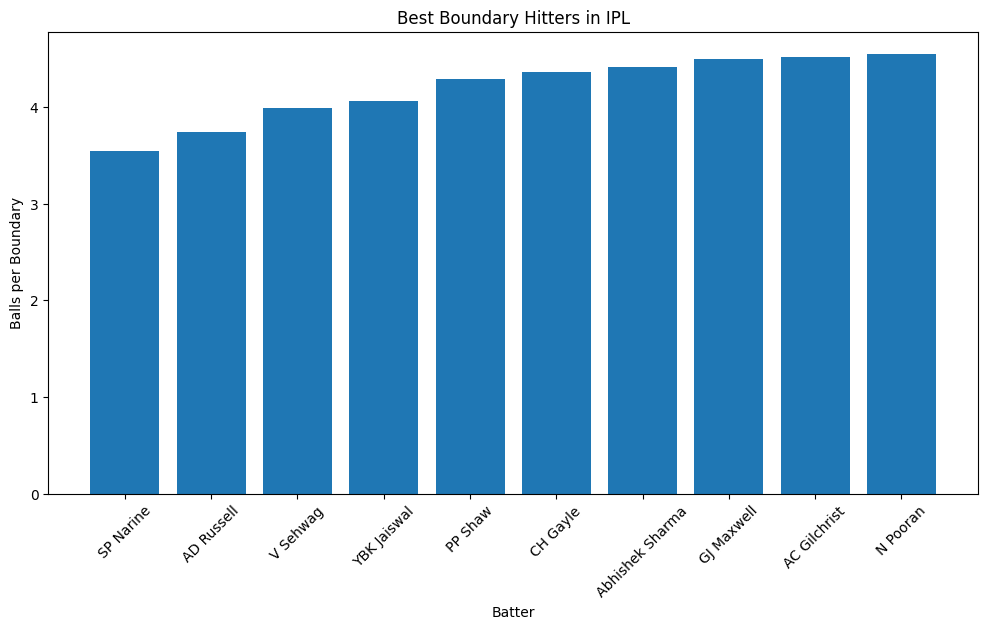

In [28]:
top_boundary_freq = (boundary_stats.sort_values(by='Boundary_Frequency').head(10))

plt.figure(figsize=(12,6))

plt.bar(
    top_boundary_freq.index,
    top_boundary_freq['Boundary_Frequency']
)

plt.title('Best Boundary Hitters in IPL')

plt.xlabel('Batter')
plt.ylabel('Balls per Boundary')

plt.xticks(rotation=45)

plt.show()

## Insight

Boundary Frequency measures how often a batter hits a boundary.

Lower values indicate more aggressive batting because the batter requires fewer balls to find the boundary.

## Business Question 5

Who are the most consistent IPL batters?

In [29]:
batter_match_runs = deliveries.groupby(['match_id', 'batter'])['batsman_runs'].sum().reset_index()

In [30]:
matches_played = batter_match_runs.groupby('batter')['match_id'].nunique()

In [31]:
total_runs = batter_match_runs.groupby('batter')['batsman_runs'].sum()

In [32]:
runs_per_match = total_runs / matches_played

In [33]:
score_30 = batter_match_runs[batter_match_runs['batsman_runs'] >= 30].groupby('batter').size()

In [34]:
score_50 = batter_match_runs[batter_match_runs['batsman_runs'] >= 50].groupby('batter').size()

In [35]:
consistency = pd.DataFrame({
    'Matches_Played': matches_played,
    'Total_Runs': total_runs,
    'Runs_Per_Match': runs_per_match,
    '30+ Scores': score_30,
    '50+ Scores': score_50
})

consistency = consistency.fillna(0)

In [36]:
consistency = consistency[consistency['Matches_Played'] >= 50]

In [37]:
consistency.sort_values(by='Runs_Per_Match', ascending=False).head(20)

,Matches_Played,Total_Runs,Runs_Per_Match,30+ Scores,50+ Scores
batter,,,,,
KL Rahul,122,4689,38.434426,60.0,41.0
RD Gaikwad,65,2380,36.615385,36.0,20.0
SE Marsh,69,2489,36.072464,37.0,21.0
DA Warner,184,6567,35.690217,96.0,66.0
CH Gayle,141,4997,35.439716,62.0,38.0
MEK Hussey,58,1977,34.086207,28.0,16.0
JC Buttler,106,3583,33.801887,41.0,26.0
F du Plessis,138,4571,33.123188,66.0,37.0
V Kohli,244,8014,32.844262,115.0,64.0


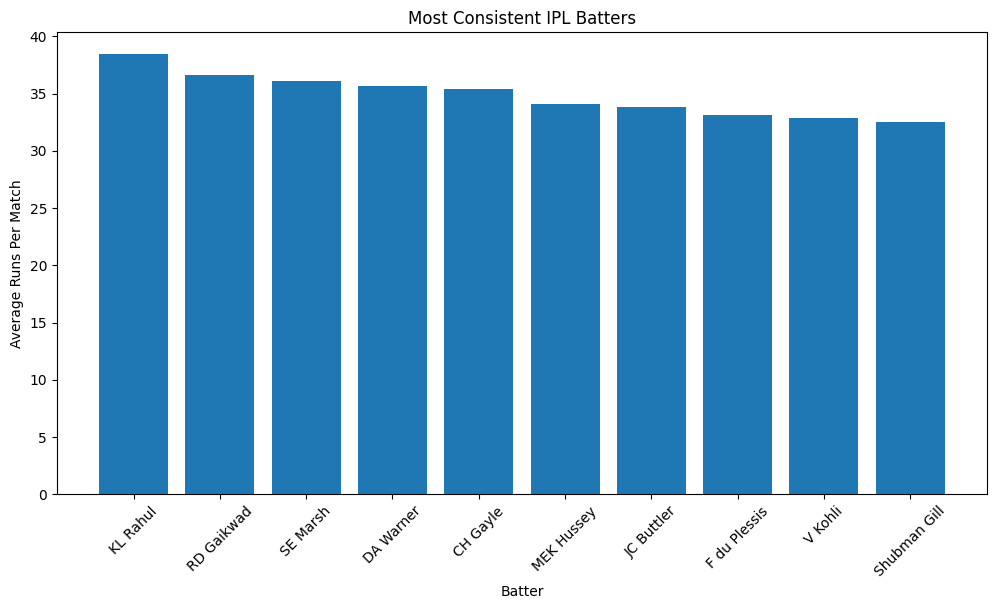

In [38]:
top_consistent = (consistency.sort_values(by='Runs_Per_Match',ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(top_consistent.index, top_consistent['Runs_Per_Match']
)

plt.title('Most Consistent IPL Batters')

plt.xlabel('Batter')
plt.ylabel('Average Runs Per Match')

plt.xticks(rotation=45)

plt.show()

## Insight

Runs per Match provides a measure of batting consistency.

Unlike total runs, this metric evaluates how much a batter contributes on average whenever they play a match.

Batters with high values tend to deliver reliable performances across seasons.

## Business Question 6

Who are the most impactful batters in IPL history?

In [39]:
impact = pd.DataFrame()

In [40]:
impact['Runs'] = batter_stats['Runs']
impact['Strike_Rate'] = batter_stats['Strike_Rate']
impact['Boundary_Runs'] = boundary_stats['Boundary_Runs']
impact['Runs_Per_Match'] = consistency['Runs_Per_Match']

In [41]:
impact = impact.fillna(0)

In [42]:
for col in impact.columns:

    impact[col + '_Score'] = ((impact[col] - impact[col].min()) / (impact[col].max() - impact[col].min())) * 100

In [43]:
impact.head(5)

,Runs,Strike_Rate,Boundary_Runs,Runs_Per_Match,Runs_Score,Strike_Rate_Score,Boundary_Runs_Score,Runs_Per_Match_Score
batter,,,,,,,,
AB de Villiers,5181,151.89,3174.0,30.476471,59.609353,66.264883,67.223065,79.294720
AC Gilchrist,2069,138.39,1508.0,25.862500,15.240947,46.420697,25.088518,67.289934
AD Russell,2488,174.84,1938.0,23.923077,21.214713,100.000000,35.963581,62.243877
AJ Finch,2092,127.95,1324.0,23.244444,15.568862,31.074526,20.435003,60.478188
AM Rahane,4642,123.42,2534.0,27.146199,51.924722,24.415699,51.036925,70.629905


In [44]:
impact['Impact_Score'] = (
      impact['Runs_Score'] * 0.40
    + impact['Strike_Rate_Score'] * 0.25
    + impact['Runs_Per_Match_Score'] * 0.25
    + impact['Boundary_Runs_Score'] * 0.10
)

In [45]:
impact.sort_values(by='Impact_Score', ascending=False).head(5)

,Runs,Strike_Rate,Boundary_Runs,Runs_Per_Match,Runs_Score,Strike_Rate_Score,Boundary_Runs_Score,Runs_Per_Match_Score,Impact_Score
batter,,,,,,,,,
V Kohli,8014,132.05,4470.0,32.844262,100.000000,37.101279,100.000000,85.455321,80.639150
DA Warner,6567,139.66,4068.0,35.690217,79.369832,48.287520,89.833080,92.860024,76.018127
CH Gayle,4997,149.34,3786.0,35.439716,56.986028,62.516537,82.701062,92.208262,69.745717
S Dhawan,6769,127.09,3990.0,30.628959,82.249786,29.810378,87.860395,79.691470,69.061416
RG Sharma,6630,131.11,4082.0,26.414343,80.268035,35.719535,90.187152,68.725737,67.237247


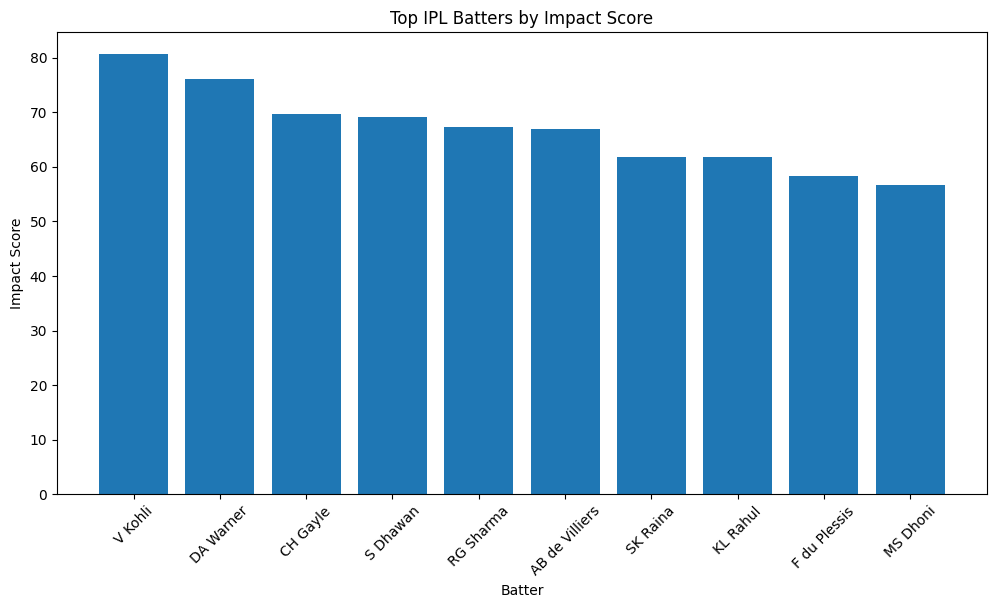

In [46]:
top_impact = (impact.sort_values(by='Impact_Score',ascending=False).head(10))

plt.figure(figsize=(12,6))

plt.bar(top_impact.index, top_impact['Impact_Score'])

plt.title('Top IPL Batters by Impact Score')

plt.xlabel('Batter')
plt.ylabel('Impact Score')

plt.xticks(rotation=45)

plt.show()

## Insight

The Batter Impact Score combines volume, efficiency, consistency, and boundary-scoring ability into a single metric.

Unlike traditional statistics, this score provides a balanced evaluation of overall batting contribution.